# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [145]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [146]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [147]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [148]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [149]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [150]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [151]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [152]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [153]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [154]:
print (plans.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes
None


In [155]:
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [156]:
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


In [157]:
usage.columns

Index(['id', 'user_id', 'type', 'date', 'duration', 'length'], dtype='object')

In [158]:
usage['type'].unique()

array(['call', 'text'], dtype=object)

In [159]:
usage[usage['type']=='call']['duration'].isna().sum()

0

In [160]:
usage[usage['type']=='text']['duration'].isna().sum()

22076

In [161]:
usage[usage['type']=='call']['length'].isna().sum()

17896

In [162]:
usage[usage['type']=='text']['length'].isna().sum()

0

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

Las columnas en users: city tiene 469 nulos, proporción 11% de los datos y churn_date tiene 3534 nulos, proporción 88% de los datos
Las columnas en usage: duration tiene 22076 nulos, proporción 55% de los datos  y length tiene 17896 nulos, proporción 44% de los datos

- Indica qué harías: ¿imputar, eliminar, ignorar?

- En el caso de *city*, haría la imputación como 'desconocido' con fillna() ya que no se puede completar la información con otras columnas del df y eliminar los datos implicaría perder información valiosa en otras columnas.
  
- En el caso de *churn_date*, un valor nulo no es necesariamente un error, sino que tiene un significado propio (cliente activo). Por eso no tiene sentido eliminarlo ni imputarlo con una fecha inventada, en su lugar, crearía una columna nueva, por ejemplo is_active, que sea True cuando churn_date es nulo y False cuando tiene una fecha

- En el caso de *duration* y *length* el nulo no significa "dato perdido" sino "esta columna no aplica a este tipo de evento". Es un nulo estructural, no un error de recolección de datos. Por eso, lo correcto es "ignorarlo" en el sentido de que no necesitamos rellenarlo con ningún valor: cuando analicemos duration, simplemente filtramos o trabajamos solo con las filas de tipo call (las de text quedan fuera naturalmente porque no tienen sentido ahí), y viceversa con length.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [163]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` es un identificador consecutivo del 10,000 al 13,999 (4,000 registros únicos sin nulos), por lo que sus métricas estadísticas no reflejan un comportamiento de uso, sino la numeración total de clientes.
- La columna `age` presenta una media de 33.7 años y una mediana de 47 años. Sin embargo, contiene un valor mínimo de -999.0 (un sentinel/error de captura de datos) que distorsiona gravemente la desviación estándar (123.23), por lo que debe limpiarse para relevar que la base se concentra en adultos y jóvenes de hasta 79 años

In [164]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` son identificadores secuenciales (con 40,000 registros en total) que van desde el 1 al 40,000 y del 10,000 al 13,999 respectivamente, por lo que sus estadísticas reflejan la numeración de los eventos y clientes, sin representar métricas de comportamiento de uso
- La columna `duration` con 17,924 registros válidos de llamadas) Muestra una duración promedio de 5.2 minutos y una mediana de 3.5 minutos, con un valor mínimo de 0.0 y un máximo de 120 minutos, lo cual indica que la mayoría de las llamadas son breves, pero existen casos extensos válidos.
- La columna `length` (con 22,104 registros de mensajes) presenta una media de 52.1 caracteres y una mediana de 50.0, con un valor máximo de 1,490 caracteres, un pico alto que funciona como un valor atípico potencial a revisar en los boxplots

In [165]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

In [166]:
columnas_user = ['city', 'plan']
users['plan'].value_counts()

Basico     2595
Premium    1405
Name: plan, dtype: int64

- La columna `city` muestra que Bogotá (808), CDMX (730) y Medellín (616) concentran la mayor cantidad de usuarios, seguida por GDL, Cali y MTY. Sin embargo, se detecta un valor inválido o sentinel representado por el signo de interrogación (?) con 96 registros
- La columna `plan` indica que el plan Basico domina la base de clientes con 2,595 usuarios, mientras que el plan Premium cuenta con 1,405 suscriptores, mostrando una preferencia clara o mayor adopción hacia el plan de menor costo

In [167]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` muestra que predominan los mensajes de texto con 22,092 registros frente a 17,908 llamadas, reflejando una preferencia equilibrada pero mayor hacia la mensajería, sin la presencia de valores nulos o categorías inválidas


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
¿En qué columnas encontraste valores inválidos o sentinels?
  
- Columna *age* en DS users, se encontró un valor mínimo de -999.0
- Columna *city* en DS users, se encontró el signo de interrogación ? con 96 registros
  
¿Qué acción tomarías?

- En el caso de *age* identificaría estos registros y los reemplazaría por la mediana excluyendo el valor sentinel, porque es una variable numérica continua, y usar la media es una estrategia común de imputación cuando el resto de los valores son razonables
- En el caso de *city* reemplazaría el valor ? por una nueva columna 'desconocido' para no inventar datos de ciudad y no afectar el resto de las variables

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [168]:
users['reg_date'] = pd.to_datetime(users['reg_date'],errors="coerce", utc=True)
users['reg_date'].dtype

datetime64[ns, UTC]

In [169]:
usage['date'] = pd.to_datetime(usage['date'],errors="coerce", utc=True)
usage['date'].dtype

datetime64[ns, UTC]

In [170]:
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

En `reg_date` , indican que los datos están registrados hasta el año 2024, pero aparece un 2026 en la lista, lo cual es un año que no debería existir en este dataset

In [171]:
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, obtenemos 2024 y nan, lo cual tiene sentido: el nan aparece porque al usar errors='coerce', cualquier fecha inválida o mal formateada se convirtió en NaT (Not a Time), así que esta columna está más "limpia" en ese sentido

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

Obtuvimos una fecha imposible (2026) en reg_date

- ¿Qué harías con ellas?

Cambiaria este valor imposible a NaT para imputarlo como 'fecha desconocida'

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [172]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].replace(-999,np.nan)
mediana = age_mediana.median()
users['age'] = users['age'].replace(-999,mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [173]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?',pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [174]:
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [175]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] [users['reg_date'].dt.year==2026] = np.nan

# Verificar cambios
users['reg_date'].describe()

count                                    3960
unique                                   3960
top       2023-12-20 18:33:45.506376600+00:00
freq                                        1
first               2022-01-01 00:00:00+00:00
last                2024-12-31 00:00:00+00:00
Name: reg_date, dtype: object

In [176]:
users['reg_date'].dt.year.unique()

array([2022.,   nan, 2023., 2024.])

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [177]:
usage.groupby('type')[['duration', 'length']].apply(lambda x: x.isna().sum())


,duration,length
type,,
call,0,17896
text,22076,0


Los nulos en *duration* y *length* no son aleatorios puros, sino que dependen completamente de la columna type (si es call, length será nulo; si es text, duration será nulo). Eso confirma que es un patrón MNAR/Estructurales, por lo que no se imputan, ni se eliminan

In [178]:
users['plan'].value_counts(dropna=False) 

Basico     2595
Premium    1405
Name: plan, dtype: int64

In [179]:
users['is_active'] = users['churn_date'].isna()
users['is_active'].value_counts()

True     3534
False     466
Name: is_active, dtype: int64

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [180]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby ('user_id').agg({'is_text':'sum','is_call':'sum','duration':'sum'}).reset_index()


# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [181]:
usage_agg = usage_agg.rename(columns={'is_text':'texts_per_user','is_call':'calls_per_user','duration':'calls_duration_per_user'})
user_profile = users.merge(usage_agg, on='user_id',how='left')

# observar resultado
user_profile.head(5)




,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,is_active,texts_per_user,calls_per_user,calls_duration_per_user
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,True,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,True,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,True,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,True,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,True,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [182]:
user_profile.describe()

,user_id,age,texts_per_user,calls_per_user,calls_duration_per_user
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


## Resumen estadístico de las columnas numéricas
- Se analizaron 4000 usuarios con una edad primedio de 48.1 años (mediana de 48 años). El 50% de los usuarios tiene entre 33 y 63 años, lo que indica una base de clientes mayoritariamente adulta y con amplia diversidad
- La actividad en el canal de mensajes de texto es relativamente homogénea: cada usuario registra en promedio 5,5 mensajes, con una mediana de 5 mensajes. Además, el 50% de los usuarios presenta entre 4 y 7 interacciones de mensajería.
- El uso del canal de llamadas también muestra un comportamiento estable, con un promedio de 4,5 llamadas por usuario y una mediana de 4 llamadas. La mitad de los usuarios realiza entre 3 y 6 llamadas, evidenciando una frecuencia de uso similar entre la mayoría de los clientes.
- La duración acumulada de las llamadas es la métrica con mayor variabilidad. Aunque la duración típica por usuario es de 19,8 minutos (mediana), existen usuarios con consumos considerablemente superiores, alcanzando hasta 155,7 minutos, lo que eleva el promedio a 23,3 minutos. Esto sugiere que las principales diferencias de comportamiento entre usuarios no están en la cantidad de llamadas realizadas, sino en el tiempo que permanecen en ellas.

In [183]:
user_profile['plan'].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

## Distribución porcentual del tipo de plan

- El 64,88% de los usuarios pertenece al plan Básico, convirtiéndolo en la opción predominante dentro de la base de clientes.
- El 35,12% de los usuarios utiliza el plan Premium, lo que indica que aproximadamente uno de cada tres usuarios ha optado por un plan de mayor nivel.
- La diferencia cercana a 30 puntos porcentuales entre ambos planes evidencia una clara concentración de usuarios en el plan Básico, que representa aproximadamente dos tercios de la base total

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

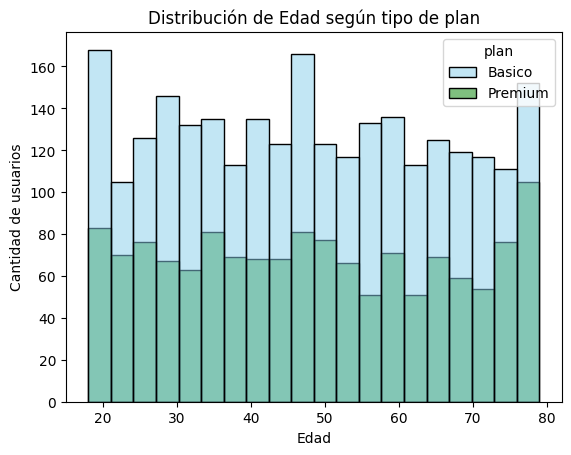

In [184]:

# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'], bins=20)
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de Edad según tipo de plan')
plt.show()


💡Insights: 
- La distribución de edades es muy similar entre los planes Básico y Premium, lo que indica que la edad no parece influir significativamente en la elección del tipo de plan. El plan Básico tiene más usuarios en todos los rangos de edad, pero el comportamiento de ambas distribuciones es bastante homogéneo.

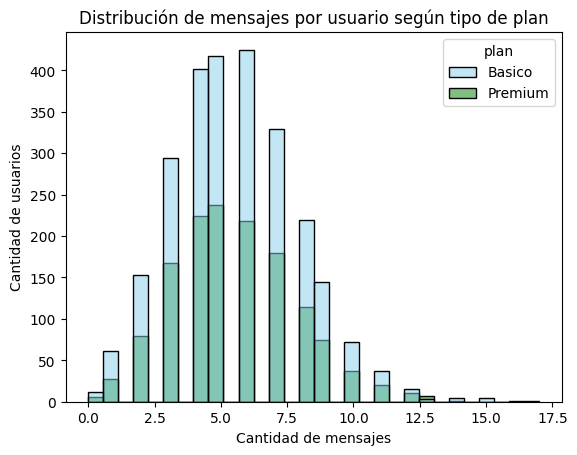

In [185]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='texts_per_user', hue='plan', palette=['skyblue','green'], bins=30)
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de mensajes por usuario según tipo de plan')
plt.show()


💡Insights: 
- Los usuarios de ambos planes concentran la mayor cantidad de mensajes entre 4 y 7 mensajes por usuario, mostrando un comportamiento muy similar. Sin embargo, los usuarios Premium tienden ligeramente a generar más mensajes, ya que mantienen una presencia relativamente mayor en los rangos altos de actividad
- La distribución está sesgada hacia la derecha, es decir, existen pocos usuarios muy activos (10+ mensajes) y muchos usuarios con niveles de actividad moderados

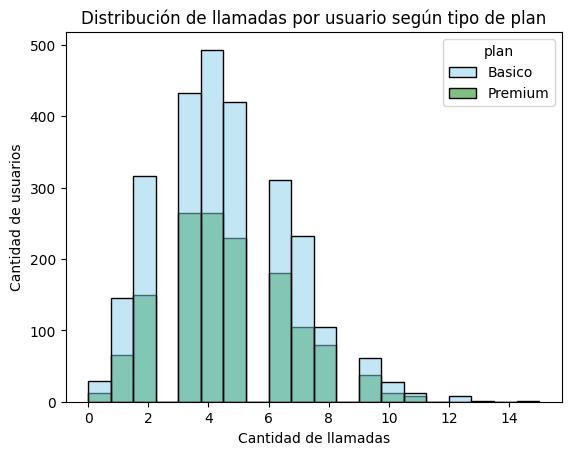

In [186]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='calls_per_user', hue='plan', palette=['skyblue','green'], bins=20)
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de llamadas por usuario según tipo de plan')
plt.show()


💡Insights: 
- La mayoría de los usuarios realiza entre 3 y 6 llamadas, independientemente del plan contratado
- La distribución de llamadas presenta un comportamiento homogéneo entre planes, con pocos usuarios de alta actividad (más de 8 llamadas)
- No existe una segmentación clara entre usuarios Básico y Premium basada en la cantidad de llamadas realizadas

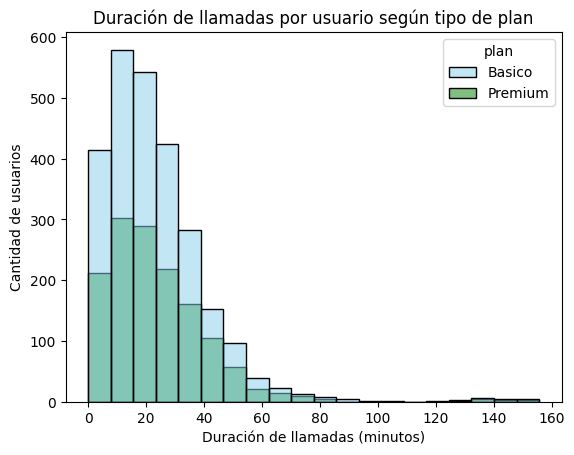

In [187]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='calls_duration_per_user', hue='plan', palette=['skyblue','green'], bins=20)
plt.xlabel('Duración de llamadas (minutos)')
plt.ylabel('Cantidad de usuarios')
plt.title('Duración de llamadas por usuario según tipo de plan')
plt.show()

💡Insights: 
- La duración de llamadas presenta una distribución sesgada hacia la derecha en ambos planes, lo que indica que la mayoría de los usuarios acumula pocos minutos de llamada y solo una minoría concentra consumos muy altos.
- Los usuarios Premium y Básico muestran patrones de uso muy similares, sin diferencias marcadas en la distribución de minutos consumidos.
La mayor concentración de usuarios se encuentra aproximadamente entre 10 y 30 minutos de llamadas.
- Existen valores atípicos (usuarios con más de 100 minutos), aunque representan una proporción muy pequeña del total

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

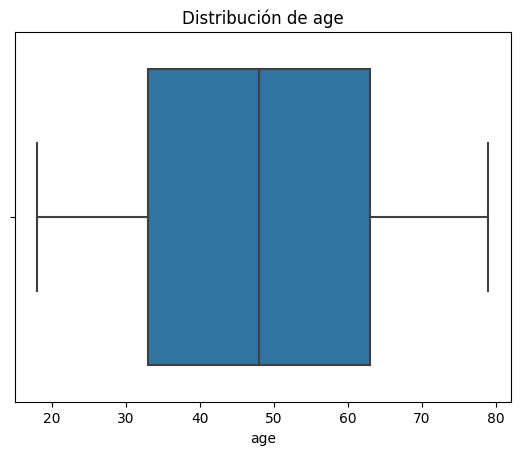

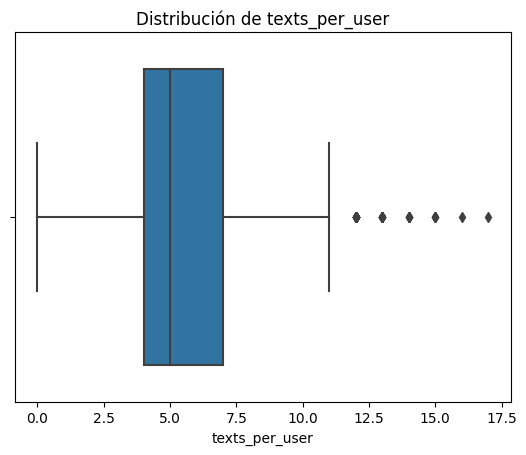

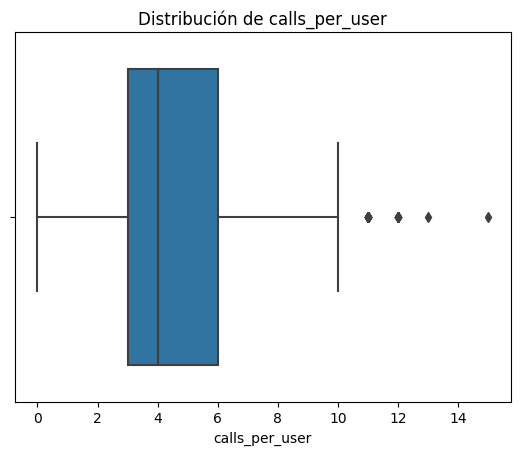

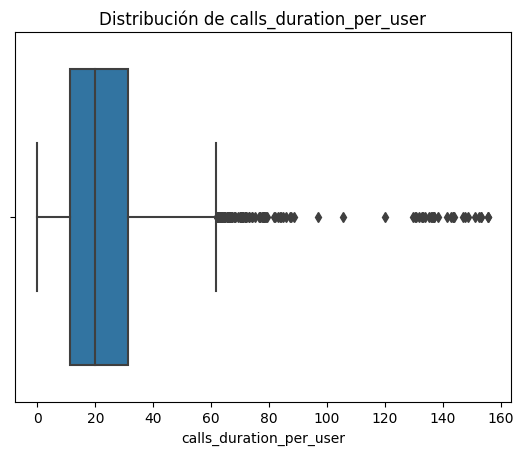

In [188]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'texts_per_user', 'calls_per_user', 'calls_duration_per_user']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Distribución de {col}')
    plt.show()


💡Insights: 
- Age: La edad presenta una distribución equilibrada entre los 18 y 80 años, sin valores extremos que sugieran registros atípicos o anomalías. No presenta outliers
- texts_per_user: La mayoría de los usuarios envía entre 4 y 7 mensajes, pero existe un pequeño grupo de usuarios significativamente más activos que alcanza hasta 17 mensajes. Sí existen outliers
- calls_per_user: La mayor parte de los usuarios realiza entre 3 y 6 llamadas, aunque algunos usuarios registran entre 11 y 15 llamadas, evidenciando un segmento de uso intensivo. Sí existen outliers
- calls_duration_per_user: La duración de llamadas muestra una fuerte concentración en consumos bajos y medios, pero existe un grupo reducido de usuarios con duraciones excepcionalmente altas (superiores a 60 minutos e incluso cercanas a 150 minutos), lo que indica una alta variabilidad en el uso del servicio. Sí existen outliers

In [189]:
# Calcular límites con el método IQR
columnas_limites = ['age', 'texts_per_user', 'calls_per_user', 'calls_duration_per_user']


for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f'\n{col}')
    print(f'Q1: {Q1:.2f}')
    print(f'Q3: {Q3:.2f}')
    print(f'IQR: {IQR:.2f}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')


age
Q1: 33.00
Q3: 63.00
IQR: 30.00
Límite inferior: -12.00
Límite superior: 108.00

texts_per_user
Q1: 4.00
Q3: 7.00
IQR: 3.00
Límite inferior: -0.50
Límite superior: 11.50

calls_per_user
Q1: 3.00
Q3: 6.00
IQR: 3.00
Límite inferior: -1.50
Límite superior: 10.50

calls_duration_per_user
Q1: 11.12
Q3: 31.41
IQR: 20.30
Límite inferior: -19.32
Límite superior: 61.86


In [190]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,texts_per_user,calls_per_user,calls_duration_per_user
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- El método IQR produjo un límite inferior de -12 años y un límite superior de 84 años. Dado que una edad negativa no es posible, el límite inferior se descartó por carecer de interpretación práctica. Por tanto, solo se evaluaron como potenciales outliers las edades superiores a 84 años, las cuales corresponden a valores plausibles y se conservaron en el análisis
- texts_per_user: mantener o no outliers, porqué? El máximo observado (17.0) supera ligeramente el límite (11.5), pero la diferencia no es extrema. Además, enviar 12-17 mensajes no parece un comportamiento imposible ni erróneo. Son usuarios más activos, no errores, por lo que conviene mantener los outliers
- calls_per_user: mantener o no outliers, porqué? El máximo (15.0) supera moderadamente el límite (10.5). Realizar 11-15 llamadas sigue siendo totalmente plausible dentro del negocio porque representan clientes de alto uso, por lo cual es conveniente mantener los outliers 
- calls_duration_per_user: mantener o no outliers, porqué? Aunque se identifican outliers en la variable calls_duration_per_user mediante el método IQR (límite superior = 61.86 minutos), los valores extremos observados parecen corresponder a consumos elevados pero plausibles dentro del contexto del negocio. Por tanto, se considera prudente conservarlos, ya que reflejan comportamientos genuinos de los usuarios y no evidencias de errores de captura o calidad de datos

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [191]:
# Crear columna grupo_uso
def grupo_uso(fila):

    if fila['calls_per_user'] < 5 and fila['texts_per_user'] < 5:
        return 'Bajo uso'
    
    elif fila['calls_per_user'] < 10 and fila['texts_per_user'] < 10:
        return 'Uso medio'
    
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(grupo_uso, axis=1)
user_profile["grupo_uso"].value_counts(normalize=True)*100

Uso medio    73.575
Bajo uso     19.450
Alto uso      6.975
Name: grupo_uso, dtype: float64

In [192]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,is_active,texts_per_user,calls_per_user,calls_duration_per_user,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,True,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,True,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,True,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,True,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,True,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [193]:
# Crear columna grupo_edad
def grupo_edad(edad):

    if edad < 30:
        return "Joven"

    elif edad < 60:
        return "Adulto"

    else:
        return "Adulto Mayor"

user_profile["grupo_edad"] = user_profile["age"].apply(grupo_edad)

In [194]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,is_active,texts_per_user,calls_per_user,calls_duration_per_user,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,True,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,True,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,True,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,True,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,True,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

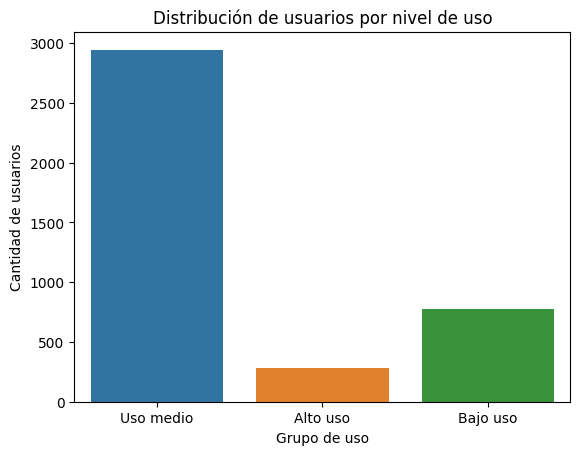

In [195]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_uso")
plt.title("Distribución de usuarios por nivel de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()

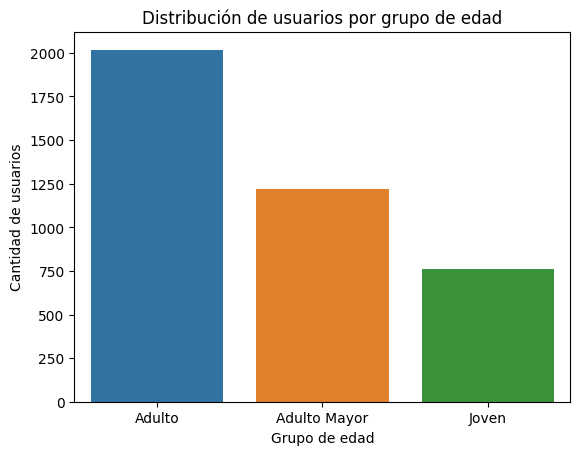

In [196]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad")
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
***¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?***

Se identificaron varios problemas de calidad de datos que requerían tratamiento antes del análisis:

- 11,7% de los registros presentaban valores faltantes en la variable ciudad, afectando la caracterización geográfica de los usuarios.
- La columna churn_date tenía aproximadamente 88,3% de valores nulos, correspondientes a clientes que permanecen activos, por lo que no se consideró un problema de calidad.
- Se detectaron valores inválidos en edad (-999) que fueron reemplazados por la mediana para evitar sesgos.
- Se identificaron registros de ciudad con el valor "?", los cuales fueron tratados como valores faltantes.
- Se encontraron fechas de registro futuras (año 2026) que fueron corregidas.
- Los nulos en duración de llamadas y longitud de mensajes correspondían a la naturaleza de cada evento (llamadas o mensajes) y fueron considerados valores estructurales esperados.
  

***¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?***

Se identificaron dos tipos principales de segmentación:

Por edad

- Jóvenes (< 30 años).
- Adultos (30 a 59 años).
- Adultos mayores (≥ 60 años).

Por nivel de uso

- Bajo uso: menos de 5 llamadas y menos de 5 mensajes.
- Uso medio: menos de 10 llamadas y menos de 10 mensajes.
- Alto uso: usuarios que superan estos niveles.

Los análisis mostraron que la edad no parece influir significativamente en la elección del plan, ya que los usuarios Básico y Premium presentan distribuciones muy similares. Asimismo, los patrones de llamadas y mensajes son relativamente homogéneos entre segmentos.


***¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?***

Los usuarios de alto uso representan el segmento más valioso, ya que concentran un mayor consumo de servicios y presentan un mayor potencial de monetización.

Particularmente relevantes son los clientes que:

- Registran una alta duración acumulada de llamadas.
- Mantienen niveles elevados de interacción mediante llamadas y mensajes.
- Superan ampliamente el comportamiento promedio de la base de usuarios.

Estos clientes constituyen candidatos ideales para estrategias de fidelización, upgrades a planes superiores y ofertas personalizadas.


***¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?***

Se identificaron outliers en:

- Cantidad de mensajes por usuario.
- Cantidad de llamadas por usuario.
- Duración de llamadas por usuario.

El caso más relevante fue la duración de llamadas, donde algunos usuarios registran consumos muy superiores al promedio.

Lejos de representar errores de captura de datos, estos valores parecen corresponder a comportamientos reales de clientes intensivos.

Implicación para el negocio: estos usuarios pueden representar segmentos de alto valor, necesidades específicas de comunicación o incluso oportunidades para diseñar planes con beneficios enfocados en consumo intensivo.


***¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?***

- Diseñar un plan premium orientado a usuarios intensivos, con mayores beneficios en minutos de llamada.
- Implementar campañas de migración dirigidas a usuarios del plan Básico con niveles de uso medio y alto.
- Crear ofertas segmentadas según comportamiento de uso en lugar de basarse únicamente en la edad, ya que esta variable no mostró diferencias significativas entre planes.
- Desarrollar programas de fidelización para usuarios de alto consumo, reduciendo el riesgo de abandono de los clientes más rentables.
- Monitorear periódicamente a los usuarios con consumos extremos para identificar oportunidades de personalización y maximizar ingresos.


✍️ **Escribe aquí tu análisis ejecutivo:**


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Se identificó un 11,7% de valores faltantes en la variable ciudad, además de registros con el valor inválido "?", los cuales fueron tratados como datos ausentes.
- Se detectaron valores erróneos en edad (-999) y fechas de registro futuras, que fueron corregidos durante el proceso de limpieza para garantizar la calidad del análisis.


🔍 **Segmentos por Edad**

- La mayor concentración de usuarios se encuentra en el segmento de adultos (30-59 años), seguido por adultos mayores y jóvenes.
- La distribución de edades es similar entre los planes Básico y Premium, lo que indica que la edad no parece ser un factor determinante en la elección del plan.

📊 **Segmentos por Nivel de Uso**

- La mayoría de los usuarios se concentra en los segmentos de uso bajo y uso medio, caracterizados por una cantidad moderada de llamadas y mensajes.
- Existe un grupo más reducido de usuarios de alto uso, que registra una frecuencia superior de llamadas, mensajes y duración de consumo, representando una oportunidad de mayor monetización.


➡️ Esto sugiere que el comportamiento de uso es un mejor criterio de segmentación que la edad. Los clientes muestran patrones de consumo similares entre planes, pero los usuarios de alto uso destacan como un segmento estratégico por su mayor nivel de interacción con los servicios.


💡 **Recomendaciones**

- Diseñar o fortalecer planes dirigidos a usuarios de alto consumo, incorporando beneficios diferenciales en llamadas y servicios adicionales.
- Implementar estrategias de migración y fidelización para usuarios del plan Básico con uso medio o alto, ya que presentan el mayor potencial de crecimiento en ingresos y rentabilidad.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`